In [2]:
import pretty_midi
import librosa
import librosa.display
import soundfile as sf

from musicProcessing import MusicProcessingProvider as mp
from alg_bins import AlgBins

from tqdm import tqdm
import os
import matplotlib.pyplot as plt
import numpy as np

from pandas import DataFrame
import pandas as pd

In [2]:
def get_source_activity(midi_path, sr, hop_length, max_frames):
    # loads individual source midi and returns a np.array with all the active time frame indexes
    pm = pretty_midi.PrettyMIDI(midi_path)
    active_frames = np.asarray([], dtype=int)
    for instrument in pm.instruments:
        for note in instrument.notes:
            start_frame = np.floor(note.start * sr / hop_length).astype(int)
            end_frame = np.floor(note.end * sr / hop_length).astype(int)
            active_frames = np.union1d(active_frames, np.arange(start_frame, end_frame))
    # clip to max_frames
    active_frames = active_frames[active_frames < max_frames]
    return active_frames

In [3]:
def similarity(arr1, arr2):
    # Jaccard similarity between two arrays of active frame indexes
    intersection = np.intersect1d(arr1, arr2).size
    union = np.union1d(arr1, arr2).size
    
    if union == 0:
        return 0.0
    return intersection / union

In [4]:
baby_slakh_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/babyslakh_16k/"
results_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/experiments/results/exp4/"
os.makedirs(results_path, exist_ok=True)
nfft = 2048
win_length = 2048
hop_length = 1024
window_type = "hann"

In [5]:
# alg params
num_generations = 400
population_size = 600
random_seed = 42
sharing_radius = 0.5
mutation_probability = 0.15
crossover_probability = 0.7
population_initialization_method = "random" # "random" or "elite"
selection_method = "tournament" # "tournament" or "roulette"
crossover_method = "two_point" # "single_point" , "two_point" or "rrc"
sim_metric = "jaccard" # "jaccard", "cosine", "cosine_blurred" or "fenotype"
Individual_bin_count = 20

In [6]:
tracks = os.listdir(baby_slakh_path)
tracks.sort()

results = DataFrame(columns=["track_id", "identified_stem_id","fitness", "similarity_to_gt"])

for track in tqdm(tracks):
    track_path = os.path.join(baby_slakh_path, track)
    os.makedirs(os.path.join(results_path, track), exist_ok=True)

    mixture_path = os.path.join(track_path, "mix.wav")
    midi_path = os.path.join(track_path, "MIDI")
    
    midi_files = [f for f in os.listdir(midi_path) if f.endswith(".mid")]
    midi_files.sort()
    
    music_processor = mp(path=mixture_path, duration=None, nfft=nfft, hop_length=hop_length, win_length=win_length, window_type=window_type)
    
    activation_patterns = {}
    for midi_file in midi_files:
        midi_file_path = os.path.join(midi_path, midi_file)
        stem_name = midi_file.replace(".mid", "")
        
        # Guard against a missing MIDI file
        if not os.path.exists(midi_file_path):
            print(f"Warning: Missing MIDI file for {midi_file}. Skipping.")
            continue
            
        active_frames = get_source_activity(midi_file_path, music_processor.sr, hop_length, music_processor.magnitude.shape[1])
        
        if len(active_frames) == 0:
            # Instead of crashing your entire pipeline, log it and move to the next stem
            print(f"Skipping {stem_name} in {track}: No active frames found in MIDI.")
            continue
        
        activation_patterns[stem_name] = active_frames
    
    #run alg on the mixture and get the estimated activation patterns
    
    alg = AlgBins(mp=music_processor, random_seed=random_seed, num_generations=num_generations, population_size=population_size, individual_bin_count=Individual_bin_count, mutation_probability=mutation_probability, crossover_probability=crossover_probability, crossover_method=crossover_method, selection_method=selection_method, sim_metric=sim_metric, sharing_radius=sharing_radius, population_initialization_method=population_initialization_method)
    alg.run()
    
    best_individual = sorted(alg.population, key=lambda ind: ind.fitness, reverse=True)[0]
    
    repetition_pattern = np.flatnonzero(best_individual.genome_bin)
    
    W = music_processor.median_filter(repetition_pattern)
    mask = music_processor.calc_mask(W)

    source_data = music_processor.apply_mask(music_processor.stft, mask)
    source_data = music_processor.calc_iSTFT(source_data, hop_length=hop_length, win_length=win_length, window_type=window_type)
    
    source_path = os.path.join(results_path, track, "estimated_source.wav")
    sf.write(source_path, source_data, music_processor.sr)
    
    best_match = None
    match_similarity = -1
    
    for stem_name, active_frames in activation_patterns.items():
        sim = similarity(repetition_pattern, active_frames)
        if sim > match_similarity:
            match_similarity = sim
            best_match = stem_name
            
    results = pd.concat([results, pd.DataFrame([{
        "track_id": track,
        "identified_stem_id": best_match,
        "fitness": best_individual.fitness,
        "similarity_to_gt": match_similarity
    }])], ignore_index=True)
    
results.to_csv(os.path.join(results_path, "results.csv"), index=False)    

  0%|          | 0/20 [00:00<?, ?it/s]/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 20/20 [1:31:20<00:00, 274.04s/it]


In [5]:
# load csv and print results
results_df = pd.read_csv(os.path.join(results_path, "results.csv"))
mean_fitness = results_df["fitness"].mean()
std_fitness = results_df["fitness"].std()
max_fitness = results_df["fitness"].max()
min_fitness = results_df["fitness"].min()
mean_similarity = results_df["similarity_to_gt"].mean()
std_similarity = results_df["similarity_to_gt"].std()
max_similarity = results_df["similarity_to_gt"].max()
min_similarity = results_df["similarity_to_gt"].min()

print(f"Mean fitness across all tracks: {mean_fitness:.4f}")
print(f"Standard deviation of fitness across all tracks: {std_fitness:.4f}")
print(f"Max fitness across all tracks: {max_fitness:.4f}")
print(f"Min fitness across all tracks: {min_fitness:.4f}")

print(f"Mean similarity to ground truth across all tracks: {mean_similarity:.4f}")
print(f"Standard deviation of similarity to ground truth across all tracks: {std_similarity:.4f}")
print(f"Max similarity to ground truth across all tracks: {max_similarity:.4f}")
print(f"Min similarity to ground truth across all tracks: {min_similarity:.4f}")

Mean fitness across all tracks: 77807.4494
Standard deviation of fitness across all tracks: 77155.7847
Max fitness across all tracks: 265594.9375
Min fitness across all tracks: 4769.7505
Mean similarity to ground truth across all tracks: 0.3677
Standard deviation of similarity to ground truth across all tracks: 0.1945
Max similarity to ground truth across all tracks: 0.7506
Min similarity to ground truth across all tracks: 0.1200


Pearson correlation coefficient: 0.7175


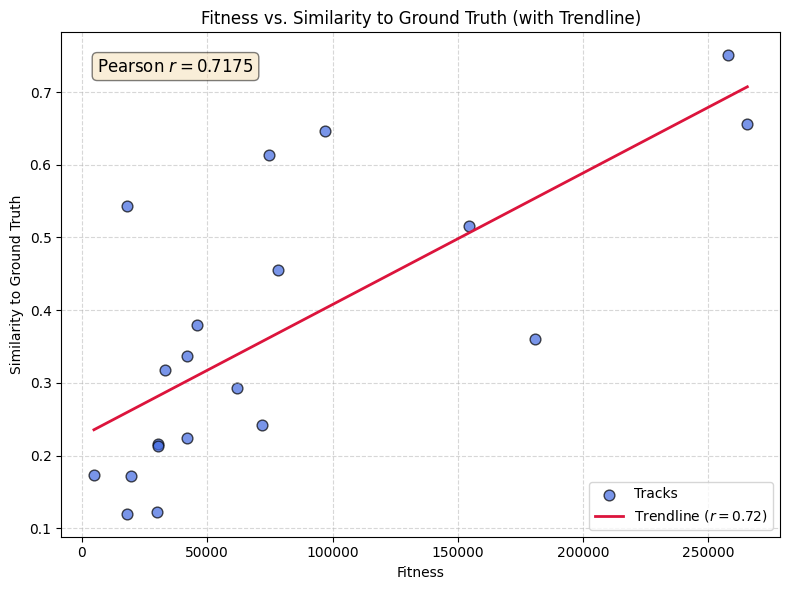

In [ ]:
# Calculate Pearson correlation coefficient
correlation = results_df["fitness"].corr(results_df["similarity_to_gt"])
print(f"Pearson correlation coefficient: {correlation:.4f}")

m, b = np.polyfit(results_df["fitness"], results_df["similarity_to_gt"], 1)

x_line = np.linspace(results_df["fitness"].min(), results_df["fitness"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    results_df["fitness"], 
    results_df["similarity_to_gt"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)
ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation:.2f}$)"
)

textstr = f"Pearson $r = {correlation:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Fitness")
ax.set_ylabel("Similarity to Ground Truth")
ax.set_title("Fitness vs. Similarity to Ground Truth (with Trendline)")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("fitness_similarity_correlation.png")
plt.show()

Pearson correlation coefficient (Similarity vs. Repetiveness): 0.0538


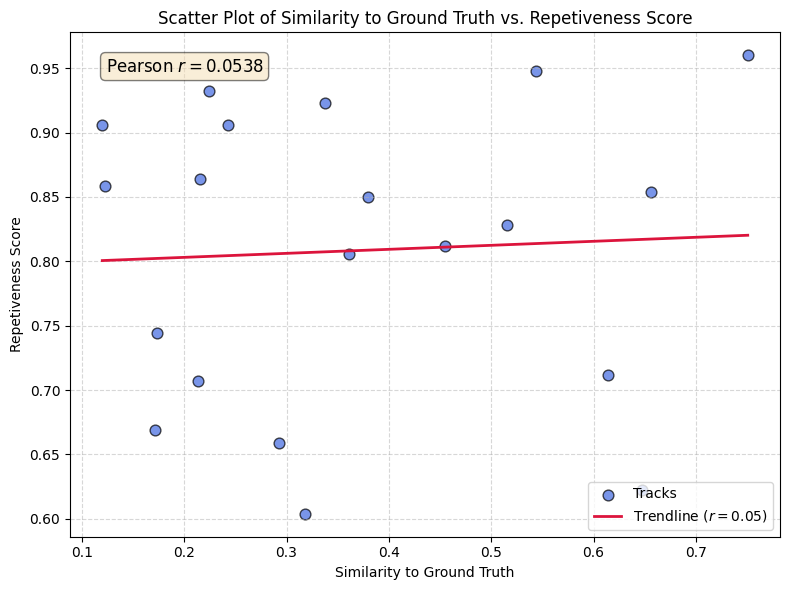

In [ ]:
# Load repetiveness data
repetiveness_scores_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/repetiveness.csv"
repetiveness_df = pd.read_csv(repetiveness_scores_path)

# Drop all cols but track_id, stem_id and score
repetiveness_df = repetiveness_df[["track_id", "stem_id", "score"]]

merged_df = pd.merge(
    results_df, 
    repetiveness_df, 
    how='left', 
    left_on=['track_id', 'identified_stem_id'], 
    right_on=['track_id', 'stem_id']
)

correlation = merged_df["similarity_to_gt"].corr(merged_df["score"])
print(f"Pearson correlation coefficient (Similarity vs. Repetiveness): {correlation:.4f}")

m, b = np.polyfit(merged_df["similarity_to_gt"], merged_df["score"], 1)

x_line = np.linspace(merged_df["similarity_to_gt"].min(), merged_df["similarity_to_gt"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    merged_df["similarity_to_gt"], 
    merged_df["score"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)

ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation:.2f}$)"
)

textstr = f"Pearson $r = {correlation:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Similarity to Ground Truth")
ax.set_ylabel("Repetiveness Score")
ax.set_title("Scatter Plot of Similarity to Ground Truth vs. Repetiveness Score")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("similarity_repetiveness_correlation.png")
plt.show()

Pearson correlation coefficient (Fitness vs. Repetiveness): 0.2013


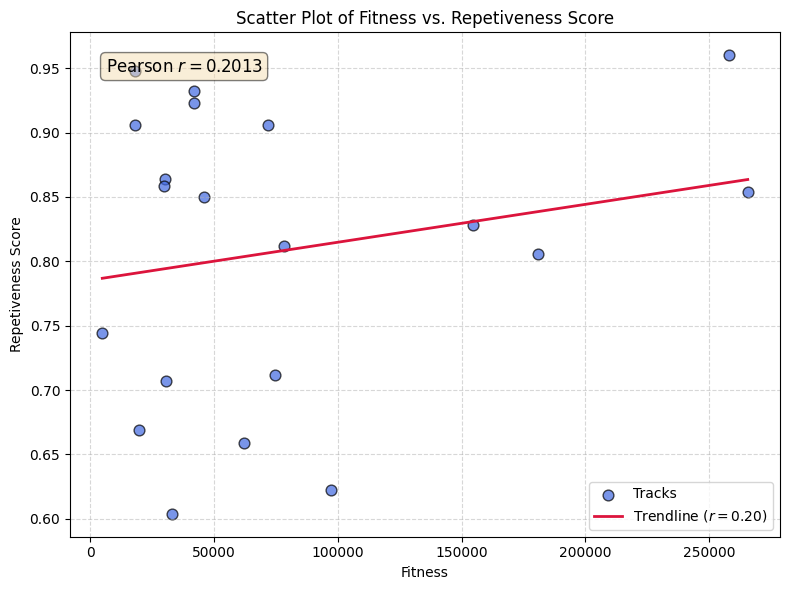

In [ ]:
correlation = merged_df["fitness"].corr(merged_df["score"])
print(f"Pearson correlation coefficient (Fitness vs. Repetiveness): {correlation:.4f}")

m, b = np.polyfit(merged_df["fitness"], merged_df["score"], 1)

x_line = np.linspace(merged_df["fitness"].min(), merged_df["fitness"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    merged_df["fitness"], 
    merged_df["score"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)

ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation:.2f}$)"
)

textstr = f"Pearson $r = {correlation:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Fitness")
ax.set_ylabel("Repetiveness Score")
ax.set_title("Scatter Plot of Fitness vs. Repetiveness Score")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("fitness_repetiveness_correlation.png")
plt.show()